In [1]:
from sklearn.datasets import load_iris
data = load_iris()
X = data.data[:,2:]
y = data.target

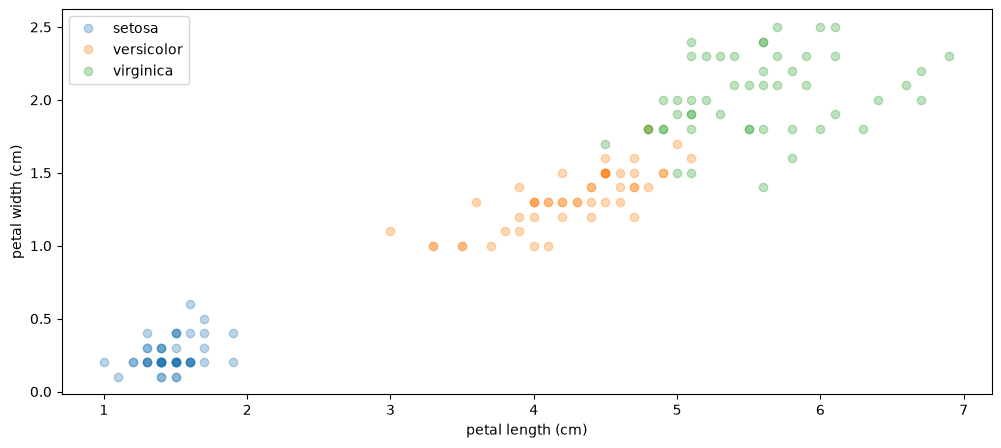

In [58]:
import matplotlib.pyplot as plt

feature_names = data.feature_names[2:4]
target_names = data.target_names

def plot_dataset(X, y, feature_names=feature_names, target_names=target_names, marker='o'):
  for i in range(len(set(y))):
    plt.plot(X[y==i,0], X[y==i, 1], marker, label=target_names[i], alpha=0.3)
  plt.xlabel(feature_names[0])
  plt.ylabel(feature_names[1])
  plt.legend()

plt.figure(figsize=(12,5))
plot_dataset(X, y)
plt.show()

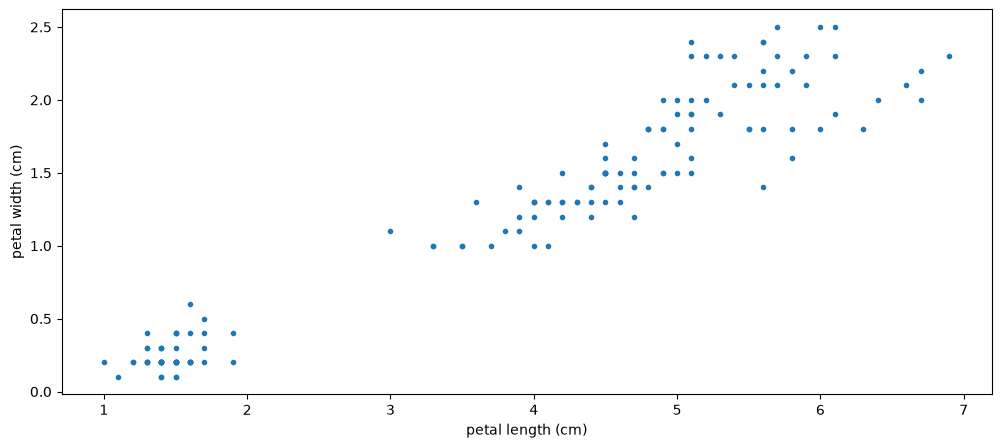

In [6]:
plt.figure(figsize=(12,5))
plt.scatter(X[:,0], X[:,1], marker='.')
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])
plt.show()

In [13]:
from sklearn.base import BaseEstimator, ClusterMixin, TransformerMixin
import numpy as np

def euclidean_distances(x, centroids):
  diff = x - centroids
  squared = diff ** 2
  summed = np.sum(squared, axis=1)
  root = np.sqrt(summed)
  return root

class KMeans(BaseEstimator, ClusterMixin, TransformerMixin):
  def __init__(self, n_clusters=3, max_iter=100, random_state=None, distances=euclidean_distances):
    self.n_clusters = n_clusters
    self.max_iter = max_iter
    self.random_state = random_state
    self.distances = distances

  def fit(self, X, y=None):
    np.random.seed(self.random_state)
    random_indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
    self.centroids_ = X[random_indices]
    self.previous_centroids_ = []
    self.previous_centroids_.append(self.centroids_.copy())
    for _ in range(self.max_iter):
      y_pred = self.predict(X)
      for i in range(self.n_clusters):
        self.centroids_[i] = np.mean(X[y_pred == i], axis=0)
      if np.allclose(self.previous_centroids_[-1], self.centroids_, atol=1e-6):
        break
      self.previous_centroids_.append(self.centroids_.copy())
    return self

  def predict(self, X):
    y_pred = np.empty((X.shape[0],))
    for i in range(X.shape[0]):
      distances = self.distances(X[i], self.centroids_)
      y_pred[i] = np.argmin(distances)
    return y_pred

kmeans = KMeans(n_clusters=3, max_iter=100, random_state=42)
kmeans.fit(X)
print("Centroids:\n", kmeans.centroids_)
print("Number of Iterations:\n", len(kmeans.previous_centroids_))

Centroids:
 [[4.29259259 1.35925926]
 [1.462      0.246     ]
 [5.62608696 2.04782609]]
Number of Iterations:
 8


In [12]:
x = np.array([1.5,2])
centroids = np.array([[1,1],[2,2],[3,3]])
euclidean_distances(x, centroids)

array([1.11803399, 0.5       , 1.80277564])

Centroids:
 [[4.26923077 1.34230769]
 [5.59583333 2.0375    ]
 [1.462      0.246     ]]
Number of Iterations:
 3


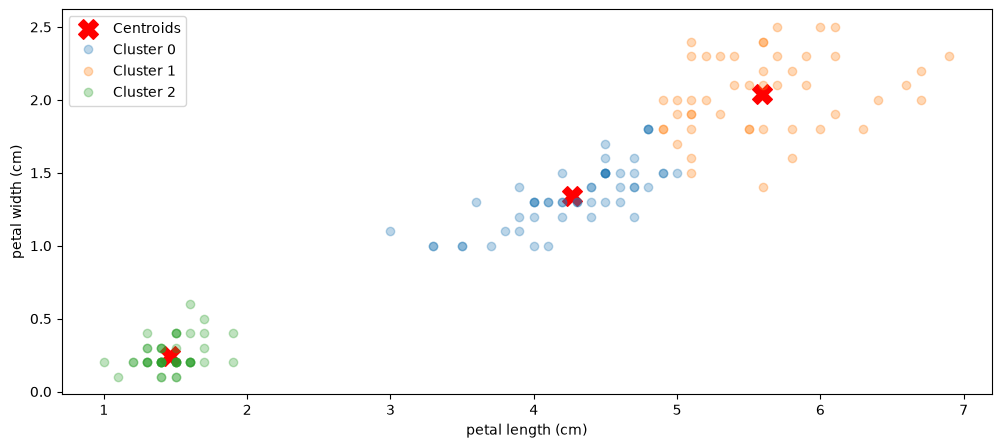

In [48]:
kmeans = KMeans(n_clusters=3, max_iter=100)
kmeans.fit(X)
print("Centroids:\n", kmeans.centroids_)
print("Number of Iterations:\n", len(kmeans.previous_centroids_))

y_pred = kmeans.predict(X)
plt.figure(figsize=(12,5))
plt.scatter(kmeans.centroids_[:,0], kmeans.centroids_[:,1], marker='X', s=200, c='red', label='Centroids')
plot_dataset(X, y_pred, feature_names=feature_names, target_names=[f'Cluster {i}' for i in range(kmeans.n_clusters)])
plt.show()


Centroids:
 [[4.26923077 1.34230769]
 [5.59583333 2.0375    ]
 [1.462      0.246     ]]
Number of Iterations:
 15


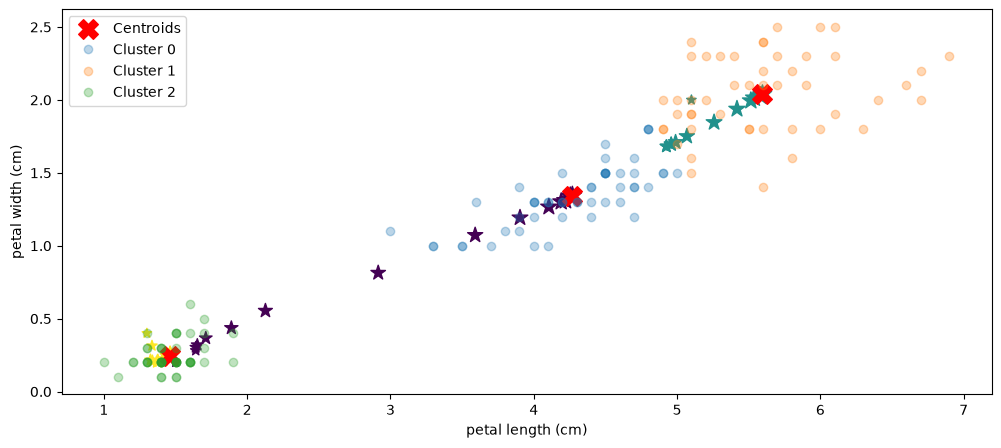

In [71]:
kmeans = KMeans(n_clusters=3, max_iter=100)
kmeans.fit(X)
print("Centroids:\n", kmeans.centroids_)
print("Number of Iterations:\n", len(kmeans.previous_centroids_))

y_pred = kmeans.predict(X)
plt.figure(figsize=(12,5))
for i in range(len(kmeans.previous_centroids_)):
  plt.scatter(kmeans.previous_centroids_[i][:,0], kmeans.previous_centroids_[i][:,1],
              marker='*', s=10*(i+5), c=list(set(y_pred)))
plt.scatter(kmeans.centroids_[:,0], kmeans.centroids_[:,1], marker='X', s=200, c='red', label='Centroids')
plot_dataset(X, y_pred, feature_names=feature_names, target_names=[f'Cluster {i}' for i in range(kmeans.n_clusters)])
plt.show()

In [72]:
def define_axes(X):
    offset = 0.1
    min1, max1 = X[:, 0].min(), X[:, 0].max()
    min2, max2 = X[:, 1].min(), X[:, 1].max()
    return [min1-offset, max1+offset, min2-offset, max2+offset]

def plot_predictions(clf, X):
    axes = define_axes(X)
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)

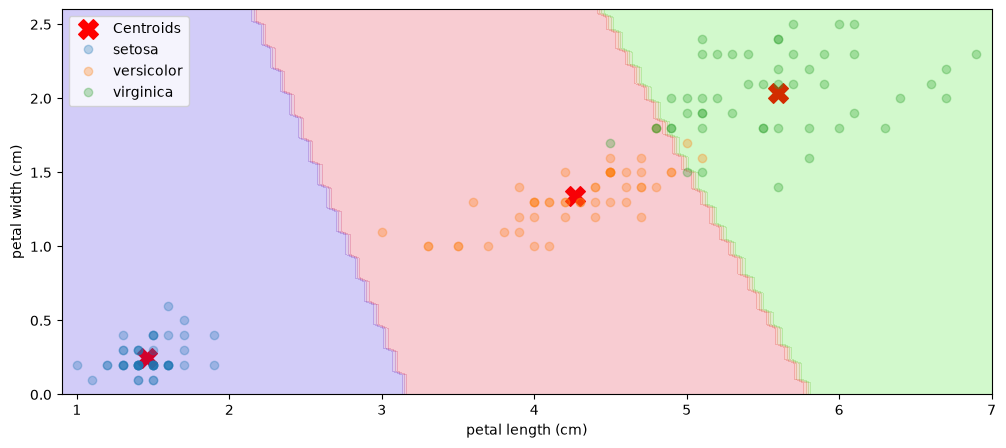

In [74]:
kmeans.fit(X)

plt.figure(figsize=(12,5))
plt.scatter(kmeans.centroids_[:,0], kmeans.centroids_[:,1], marker='X', s=200, c='red', label='Centroids')
plot_dataset(X, y)
plot_predictions(kmeans, X)
plt.show()